# MNIST Classification (Embedded)

Loads MNIST via scikit-learn's `fetch_openml`, trains a simple MLP classifier with PyTorch Lightning, and evaluates on the held-out test set.

In [69]:
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import lightning as L
from torchmetrics import Accuracy
from sklearn.datasets import fetch_openml

L.seed_everything(42)

Seed set to 42


42

## Load MNIST

`fetch_openml` downloads and caches the dataset on first run. `mnist_784` preserves the original
MNIST ordering, so the first 60,000 rows are the standard train split and the last 10,000 are the
standard test split.

In [70]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(np.int64)

X_train_full, y_train_full = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

print(X_train_full.shape, y_train_full.shape, X_test.shape, y_test.shape)

(60000, 784) (60000,) (10000, 784) (10000,)


## Normalize and build datasets

Pixel values are cast from `float64` in `[0, 255]` to `float32` in `[0, 1]`. The 60,000-row train
pool is split into train/validation subsets.

In [71]:
X_train_full = (X_train_full / 255.0).astype(np.float32)
X_test = (X_test / 255.0).astype(np.float32)

full_ds = TensorDataset(torch.from_numpy(X_train_full), torch.from_numpy(y_train_full))
test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

val_size = 6000
train_ds, val_ds = random_split(
    full_ds, [len(full_ds) - val_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

len(train_ds), len(val_ds), len(test_ds)

(54000, 6000, 10000)

## Sanity check: visualize a few training digits

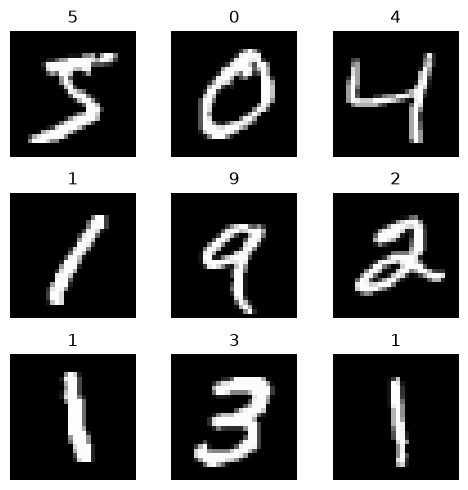

In [72]:
fig, axes = plt.subplots(3, 3, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_full[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train_full[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

## DataLoaders

In [73]:
BATCH_SIZE = 128

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

## Net(s)

In [74]:
def DenseNet():
    return nn.Sequential(
        nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(128, 10),
)

## ResNet (alternative to DenseNet)

A minimal convolutional ResNet. Each `ResidualBlock` is a single
`Conv2d (zero padding) -> BatchNorm2d`, added to a skip connection (identity, or a `1x1`
projection when channels change), followed by `ReLU`. The flattened `(N, 784)` input is
reshaped to `(N, 1, 28, 28)` inside the model so the rest of the pipeline (DataLoaders,
calibration reader, ONNX export) doesn't need to change.

In [75]:
import torch.nn.utils.prune as prune

class TaylorStructured(prune.BasePruningMethod):

    PRUNING_TYPE = "structured"
 
    def __init__(self, amount, dim=0):
        self.amount = amount
        self.dim = dim

    def compute_mask(self, t: torch.Tensor, default_mask):

        dims_to_reduce = [d for d in range(t.dim()) if d != self.dim]
        channel_score = t.mean(dim=dims_to_reduce) if dims_to_reduce else t
 
        tensor_size = t.shape[self.dim]
        n_prune = int(self.amount * tensor_size) if isinstance(self.amount, float) else self.amount
        n_prune = max(0, min(n_prune, tensor_size - 1))
        n_keep = tensor_size - n_prune
 
        if n_prune == 0:
            return default_mask
 
        keep_idx = torch.topk(channel_score, k=n_keep, largest=True).indices
        mask = torch.zeros_like(t)
        slc = [slice(None)] * t.dim()
        slc[self.dim] = keep_idx
        mask[tuple(slc)] = 1
        return mask * default_mask

    @classmethod
    def apply(cls, module, name, amount, dim, importance_scores):
        return super().apply(module, name, amount, dim=dim, importance_scores=importance_scores)

In [76]:
from torch.nn.utils.fusion import fuse_conv_bn_eval as fuse_conv_bn

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels, batch_norm=True):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=2, padding=1, padding_mode='zeros', bias=True, # convolution layer.
        )
        if batch_norm:
            self.bn = nn.BatchNorm2d(out_channels)
        else:
            self.bn = None
        self.relu = nn.ReLU()

    def forward(self, x):
        xc = self.conv(x)
        if self.bn is not None:
            xc = self.bn(xc)
        return self.relu(xc)

    @property
    def weight_mask(self):
        if hasattr(self.conv, "weight_mask"):
            return self.conv.weight_mask
        else:
            return None

    def prune(self, unit_scores, amount, dim=0):
        """Structurally prunes `module.weight` by Taylor importance, then derives
        and applies `module.bias`'s mask directly from weight's resulting alive
        channels (via prune.custom_from_mask) rather than pruning bias
        independently.
        """
        param = self.conv.weight
        shape = [1] * param.dim()
        shape[dim] = -1
        imp = unit_scores.view(*shape).expand_as(param).contiguous()
        TaylorStructured.apply(self.conv, "weight", amount=amount, dim=dim, importance_scores=imp)
    
        reduce_dims = [d for d in range(param.dim()) if d != dim]
        alive = self.conv.weight_mask.any(dim=reduce_dims) if reduce_dims else self.conv.weight_mask
        prune.custom_from_mask(self.conv, "bias", alive.float())

    def compact(self):
        # fuse the bacth-norm with the conv layer
        if self.bn is not None:
            module = fuse_conv_bn(self.conv, self.bn)
        else:
            module = self.conv

        # return the mask and the parameters.
        keep = module.weight_mask.flatten(1).any(dim=1).nonzero().squeeze(1)
        weight_data = module.weight.data[keep].clone()
        bias_data = module.bias.data[keep].clone()

        # remove from the pruning registry
        if prune.is_pruned(self):
            prune.remove(self.conv, "weight")
            prune.remove(self.conv, "bias")

        return keep, weight_data, bias_data

    def load_weight(self, weight, bias):
        self.conv.load_state_dict(dict(
            weight=weight.clone(),
            bias=bias.clone(),
        ))

class CNNet(nn.Module):

    block1: ConvBlock
    block2: ConvBlock
    fc: nn.Linear
        
    def __init__(self, c1=8, c2=16, batch_norm=True):
        # initiate.
        super().__init__()

        # self.unflatten = nn.Unflatten(1, (1, 28, 28))
        self.block1 = ConvBlock(1, c1, batch_norm=batch_norm) # 14 x 14
        self.block2 = ConvBlock(c1, c2, batch_norm=batch_norm) # 7 x 7
        self.flatten = nn.Flatten()
        self._kernel_hw = 7 * 7 
        self.fc = nn.Linear(c2 * self._kernel_hw, 10)

        # prunning
        self._capture = False
        self._activations: dict[str:torch.Tensor] = {}

    def forward(self, x: torch.Tensor):
        # x = self.unflatten(x)
        x = self.block1(x)
        if self._capture:
            x.retain_grad()
            self._activations["h1"] = x

        x = self.block2(x)
        if self._capture:
            x.retain_grad()
            self._activations["h2"] = x

        x = self.flatten(x)
        return self.fc(x)

    def compact(self):
        # set module to eval.
        training = self.training
        self.eval()

        # compact the convolution layer.
        keep_1, weight_data_1, bias_data_1 = self.block1.compact()
        keep_2, weight_data_2, bias_data_2 = self.block2.compact()

        # create new net.
        new = CNNet(c1=len(keep_1), c2=len(keep_2), batch_norm=False)

        # populate new compact weight.
        new.block1.load_weight(
            weight_data_1, bias_data_1
        )
        new.block2.load_weight(
            weight_data_2[:, keep_1], bias_data_2
        )

        flat_idx = torch.cat([torch.arange(c * self._kernel_hw, (c + 1) * self._kernel_hw) for c in keep_2])
        new.fc.weight.data = self.fc.weight.data[:, flat_idx].clone()
        new.fc.bias.data = self.fc.bias.data.clone()

        if training:
            self.train()
        
        return new

## Model

A simple fully-connected network: `784 -> 256 -> 128 -> 10` with ReLU activations and dropout.

In [ ]:
class MNISTClassifier(L.LightningModule):

    def __init__(self, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.unflatten = nn.Unflatten(1, (1, 28, 28))
        self.net = CNNet()  # swap back to DenseNet() to use the MLP baseline
        self.loss_fn = nn.CrossEntropyLoss()
        self.train_acc = Accuracy(task="multiclass", num_classes=10)
        self.val_acc = Accuracy(task="multiclass", num_classes=10)
        self.test_acc = Accuracy(task="multiclass", num_classes=10)
        self.prune_acc = Accuracy(task="multiclass", num_classes=10)

    def forward(self, x):
        x = self.unflatten(x)
        return self.net(x)

    def _step(self, batch, acc_metric, stage):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc_metric(logits, y)
        self.log(f"{stage}_loss", loss, prog_bar=True, on_epoch=True, on_step=False)
        self.log(f"{stage}_acc", acc_metric, prog_bar=True, on_epoch=True, on_step=False)
        return loss

    def training_step(self, batch, batch_idx):
        return self._step(batch, self.train_acc, "train")

    def validation_step(self, batch, batch_idx):
        self._step(batch, self.val_acc, "val")

    def test_step(self, batch, batch_idx):
        self._step(batch, self.test_acc, "test")

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.hparams.lr)
        #scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5)
        return {"optimizer": optimizer, "lr_scheduler": scheduler}

In [78]:
def compute_taylor_scores(model: MNISTClassifier,  batch):

    was_training = model.training
    model.train()
    with torch.enable_grad():
        model.zero_grad(set_to_none=True)
        model.net._capture = True
        loss = model._step(batch, model.prune_acc, "prun")
        loss.backward()
        scores = {}
        for name, act in model.net._activations.items():
            raw = (act.grad * act).abs()
            reduce_dims = tuple(d for d in range(raw.dim()) if d != 1)
            raw = raw.mean(dim=reduce_dims) if reduce_dims else raw
            scores[name] = raw / (raw.norm(p=2) + 1e-8)
        model.net._capture = False
        model.net._activations = {}
    model.zero_grad(set_to_none=True)
    model.train(was_training)
    return scores

class TaylorPruneCallback(L.Callback):
    """
    Every `every_n_epochs`, scores + structurally masks a fraction of units
    from h2 then h1 (downstream-first -- see prior discussion: masking h2
    doesn't disturb h1's forward activations, so h1's scores computed right
    after are not stale). Halts permanently once val_acc drops more than
    `acc_tolerance` below the pre-pruning baseline.
    """
 
    def __init__(
        self, calib_batch, layer_names=("block1", "block2"),
        score_keys=("h1", "h2"), frac_per_round=0.15,
        every_n_epochs=10, acc_tolerance=0.05, max_rounds=6
        ):

        self.calib_bacth = calib_batch
        self.layer_names = list(layer_names)
        self.score_keys = list(score_keys)
        self.frac = frac_per_round
        self.every_n_epochs = every_n_epochs
        self.acc_tolerance = acc_tolerance
        self.max_rounds = max_rounds
        self.rounds_done = 0
        self.baseline_acc = None
        self.stopped = False
 
    def on_validation_epoch_end(self, trainer, pl_module: MNISTClassifier):
        if trainer.sanity_checking:
            return  # this is the pre-training sanity pass on an untrained model, not real val
 
        if self.baseline_acc is None:
            self.baseline_acc = trainer.callback_metrics.get("val_acc", torch.tensor(1.0)).item()
 
        if self.stopped or self.rounds_done >= self.max_rounds:
            return
        if trainer.current_epoch == 0 or trainer.current_epoch % self.every_n_epochs != 0:
            return
 
        # downstream-first: reverse layer order
        for lname, skey in zip(reversed(self.layer_names), reversed(self.score_keys)):
            scores = compute_taylor_scores(pl_module, self.calib_bacth)
            layer: ConvBlock = getattr(pl_module.net, lname)
            layer.prune(scores[skey], self.frac, dim=0)
 
        self.rounds_done += 1
        acc = trainer.callback_metrics.get("val_acc", torch.tensor(1.0)).item()
        status = ", ".join(
            f"{ln}_alive={getattr(pl_module.net, ln).weight_mask.flatten(1).any(dim=1).sum().item()}"
            for ln in self.layer_names
        )
        print(f"[prune round {self.rounds_done}] epoch={trainer.current_epoch} "
              f"{status} val_acc={acc:.3f}")
 
        if acc < self.baseline_acc - self.acc_tolerance:
            print(f"  stopping further pruning: val_acc {acc:.3f} < "
                  f"tolerance floor {self.baseline_acc - self.acc_tolerance:.3f}")
            self.stopped = True
 
    

## Train

In [79]:
from lightning.pytorch.callbacks import TQDMProgressBar

class CustomProgressBar(TQDMProgressBar):
    def init_validation_tqdm(self):
        bar = super().init_validation_tqdm()
        bar.set_description('Running validation...')
        return bar

calib_batch = next(iter(train_loader))

prune_cb = TaylorPruneCallback(calib_batch, frac_per_round=0.15, every_n_epochs=10, acc_tolerance=0.025, max_rounds=10)

In [80]:
model = MNISTClassifier(lr=1e-3)
trainer = L.Trainer(
    max_epochs=100,
    accelerator="cpu",
    devices=1,
    logger=True,
    enable_progress_bar=True,
    callbacks=[CustomProgressBar(), prune_cb]
)
trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ unflatten │ Unflatten          │      0 │ train │     0 │
│ 1 │ net       │ CNNet              │  9.1 K │ train │     0 │
│ 2 │ loss_fn   │ CrossEntropyLoss   │      0 │ train │     0 │
│ 3 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 4 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 5 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
│ 6 │ prune_acc │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 9.1 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 9.1 K                                                                                                
Total estimated model params size (MB): 0.037                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking DataLoader 0:  50%|█████     | 1/2 [00:00<00:00, 124.99it/s]

c:\Users\thoma\anaconda3\envs\gaze\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\thoma\anaconda3\envs\gaze\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


c:\Users\thoma\anaconda3\envs\gaze\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Epoch 99: 100%|██████████| 422/422 [00:13<00:00, 32.39it/s, v_num=46, val_loss=0.0868, val_acc=0.974, train_loss=0.0487, train_acc=0.983, prun_loss=0.145, prun_acc=0.953]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

c:\Users\thoma\anaconda3\envs\gaze\Lib\site-packages\IPython\core\interactiveshell.py:3756: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Test

In [81]:
trainer.test(model, dataloaders=test_loader)

c:\Users\thoma\anaconda3\envs\gaze\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\thoma\anaconda3\envs\gaze\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Testing DataLoader 0: 100%|██████████| 79/79 [00:00<00:00, 124.96it/s]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9783999919891357     │
│         test_loss         │    0.06908175349235535    │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 0.06908175349235535, 'test_acc': 0.9783999919891357}]

In [82]:
compact_net = model.net.compact()

## Visualize predictions on the test set

In [63]:
x_batch.shape

torch.Size([128, 784])

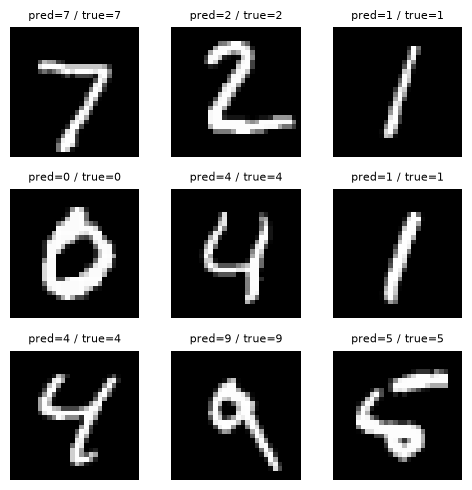

In [83]:
compact_net.eval()
x_batch, y_batch = next(iter(test_loader))
with torch.no_grad():
    preds = compact_net(x_batch.reshape(128, 1, 28, 28)).argmax(dim=1)

fig, axes = plt.subplots(3, 3, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_batch[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"pred={preds[i].item()} / true={y_batch[i].item()}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## ONNX

In [84]:
# the missing layer and place the argmax
class FullModel(nn.Module):

    def __init__(self, net):
        super().__init__()
        self.net = net
        self.eval()

    def forward(self, x):
        y = self.net((x/255.0))
        return torch.argmax(y)

full_model = FullModel(compact_net)

In [ ]:
x_batch[0].reshape(1, 1, 28,28).shape

In [85]:
example = x_batch[3].reshape(1, 1, 28,28) * 255.0
y = full_model(example)
print(y)

tensor(0)


In [86]:
from pathlib import Path
import time

path = Path("./models") / str(int(time.time()))
path.mkdir(parents=True, exist_ok=True)

# use the full_model (includes scaling and argmax); export saves directly to file
fpath = path / "mnist_classifier.onnx"

example = x_batch[3].reshape(1, 1, 28,28) * 255.0

onnx_program = torch.onnx.export(
    full_model,
    example,
    str(fpath),
    export_params=True,
    opset_version=18,
    input_names=["input"],
    output_names=["pred"],
)

W0807 22:38:41.120000 34044 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W0807 22:38:41.204000 34044 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W0807 22:38:41.204000 34044 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W0807 22:38:41.204000 34044 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `FullModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `FullModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


c:\Users\thoma\anaconda3\envs\gaze\Lib\copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


In [ ]:
from onnxsim import simplify
import onnx

onnx_model = onnx.load(fpath)
onnx_model_simplified, check = simplify(onnx_model)
onnx.save(onnx_model_simplified, path / "mnist_classifier_simplified.onnx")

In [ ]:
from onnxruntime.quantization import shape_inference

shape_inference.quant_pre_process(
    input_model_path=path / "mnist_classifier.onnx",
    output_model_path=path / "mnist_classifier_preprocessed.onnx",
    skip_optimization=False,      # set True if optimizer pass causes issues
    skip_onnx_shape=False,
    skip_symbolic_shape=False,
    auto_merge=True,             # merge conflicting symbolic shapes automatically
    verbose=2,                    # 1 or 2 for debug output
)